<a href="https://colab.research.google.com/github/Angelinat3/244107020076-mobile-course/blob/main/JS08/JS08_Lab1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Silhouette Score: 0.5148
Davies-Bouldin Index (DBI): 0.6810


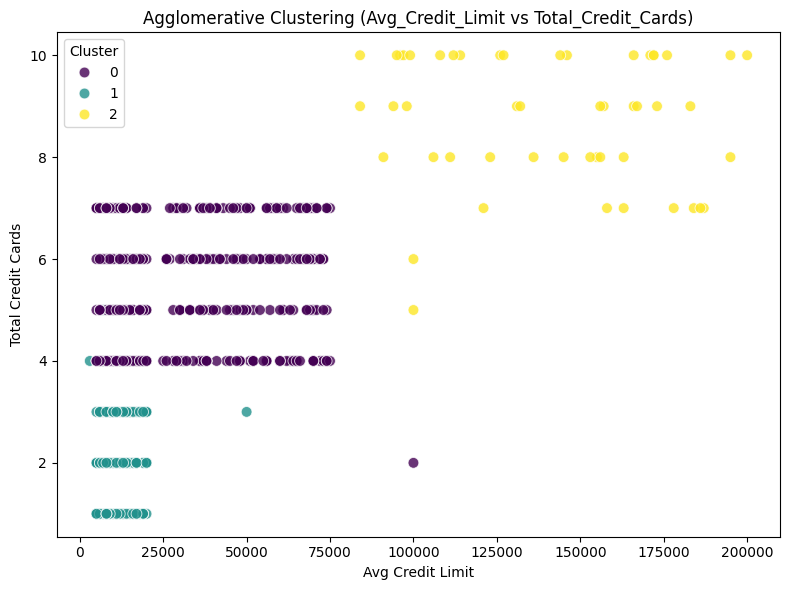

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score

# 1. Load dataset
df = pd.read_csv('CC_Customer_Dataset.csv')

# 2. Pilih variabel yang bisa digunakan (drop kolom non-fitur)
X_features = df.drop(columns=['Sl_No', 'Customer Key'])

# 3. Standardisasi fitur
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_features)

# 4. Buat model Agglomerative Clustering
agg = AgglomerativeClustering(n_clusters=3)
labels = agg.fit_predict(X_scaled)

# 5. Hitung Silhouette Score dan Davies-Bouldin Index
sil_score = silhouette_score(X_scaled, labels)
dbi_score = davies_bouldin_score(X_scaled, labels)

print(f"Silhouette Score: {sil_score:.4f}")
print(f"Davies-Bouldin Index (DBI): {dbi_score:.4f}")

# 6. Buat scatterplot berdasarkan Avg_Credit_Limit dan Total_Credit_Cards
plt.figure(figsize=(8, 6))
sns.scatterplot(
    x=df['Avg_Credit_Limit'],
    y=df['Total_Credit_Cards'],
    hue=labels,
    palette='viridis',
    s=60,
    alpha=0.8
)
plt.title('Agglomerative Clustering (Avg_Credit_Limit vs Total_Credit_Cards)')
plt.xlabel('Avg Credit Limit')
plt.ylabel('Total Credit Cards')
plt.legend(title='Cluster')
plt.tight_layout()
plt.show()